# 06 — Forecasts: backtest, conformal intervals and 2026 cheese scenarios

Next step 5 in `CONTRIBUTING.md` (decisions D06, D08, D09, D10, D23). Logic: `src/forecast/models.py`.
- Models: seasonal naive (baseline), damped ETS per series, global LightGBM [F1, F2].
- Rolling-origin backtest only: origins every 3 months from 2019-01 to 2025-08, horizons 1–12 months [F3].
- Metrics: MASE and sMAPE. Intervals: split conformal on log errors, calibrated on 2019–2022 origins, coverage checked on 2023–2025 origins [F4].
- 2026 cheese scenarios: baseline forecast + tariff × exposure × pass-through (25%, 60%, 70%), D06.

In [1]:
import sys
from pathlib import Path
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(root / "src"), str(root / "src" / "forecast"), str(root / "src" / "causal")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import models as M
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
panel = M.food_panel()
print(f"{panel.shape[1]} national food series, last month {panel.index.max()}")

101 national food series, last month 2026-08


## 1. Rolling-origin backtest

In [2]:
origins = list(pd.period_range("2019-01", "2025-08", freq="M")[::3])
bt = M.backtest(panel, origins)
bt.to_csv(root / "data/processed/backtest.csv", index=False)
print(len(origins), "origins,", len(bt), "forecast-actual pairs")
overall = bt.groupby("model")[["mase", "smape"]].mean().sort_values("mase")
overall.round(3)

27 origins, 98172 forecast-actual pairs


,mase,smape
model,,
lightgbm,1.283,3.205
ets,1.365,3.373
seasonal_naive,2.160,5.197


In [3]:
by_h = bt[bt.h.isin([1, 3, 6, 12])].pivot_table(index="h", columns="model", values="mase", aggfunc="mean")
by_h.round(3)

model,ets,lightgbm,seasonal_naive
h,,,
1,0.607,0.646,2.045
3,0.946,0.931,2.092
6,1.308,1.253,2.176
12,2.039,1.823,2.237


In [4]:
# Share of series where each model has the lowest MASE (averaged over origins and horizons)
per_series = bt.groupby(["series", "model"]).mase.mean().unstack()
per_series.idxmin(axis=1).value_counts(normalize=True).round(3)

lightgbm    0.752
ets         0.248
Name: proportion, dtype: float64

## 2. Conformal intervals: calibrate on 2019–2022 origins, check coverage on 2023–2025

In [5]:
cut = pd.Period("2023-01", "M")
q_cal = M.conformal_quantiles(bt[bt.origin < cut])
cov = M.coverage(bt[bt.origin >= cut], q_cal)
cov.round(3)

,coverage_80,coverage_95
model,,
ets,0.853,0.960
lightgbm,0.870,0.970
seasonal_naive,0.875,0.977


In [6]:
q_all = M.conformal_quantiles(bt)   # final quantiles use every origin
q_all.to_csv(root / "data/processed/conformal_quantiles.csv", index=False)
q_all[q_all.h.isin([1, 3, 6, 12])].round(4)

,model,h,n_cal,q80,q95
0,ets,1,2727,0.0257,0.0498
2,ets,3,2727,0.0389,0.0752
5,ets,6,2727,0.0513,0.0941
11,ets,12,2727,0.0755,0.1340
12,lightgbm,1,2727,0.0273,0.0535
14,lightgbm,3,2727,0.0383,0.0755
17,lightgbm,6,2727,0.0506,0.0893
23,lightgbm,12,2727,0.0702,0.1227
24,seasonal_naive,1,2727,0.0820,0.1382
26,seasonal_naive,3,2727,0.0826,0.1394


## 3. Final 12-month forecasts (simplest model within 5% of the best MASE, D24)

In [7]:
# D24: use the simplest model whose mean MASE is within 5% of the best one (easier to explain)
SIMPLICITY = ["seasonal_naive", "ets", "lightgbm"]
best_mase = overall.mase.min()
best = next(m for m in SIMPLICITY if overall.loc[m, "mase"] <= 1.05 * best_mase)
print("Lowest MASE:", overall.index[0], round(best_mase, 3), "| model used (simplest within 5%):", best, round(overall.loc[best, "mase"], 3))
fc = M.forecast_all(panel, best, q_all)
fc.to_csv(root / "data/processed/forecasts.csv", index=False)
print("Model used:", best)
fc[fc.series.isin(["Food", "Food purchased from stores", "Cheese", "Fresh milk", "Fresh or frozen beef", "Fresh vegetables"]) & fc.h.isin([4, 12])].round(1)

Lowest MASE: lightgbm 1.283 | model used (simplest within 5%): lightgbm 1.283


Model used: lightgbm


,series,month,h,forecast,model,lo80,hi80,lo95,hi95
231,Cheese,2026-12,4,159.5,lightgbm,152.9,166.3,147.4,172.6
239,Cheese,2027-08,12,162.5,lightgbm,151.5,174.4,143.8,183.8
411,Food,2026-12,4,203.2,lightgbm,194.8,212.0,187.8,219.9
419,Food,2027-08,12,208.5,lightgbm,194.4,223.7,184.4,235.7
459,Food purchased from stores,2026-12,4,200.1,lightgbm,191.9,208.7,184.9,216.6
467,Food purchased from stores,2027-08,12,205.3,lightgbm,191.4,220.3,181.6,232.2
495,Fresh milk,2026-12,4,186.9,lightgbm,179.2,194.9,172.7,202.3
503,Fresh milk,2027-08,12,191.6,lightgbm,178.6,205.5,169.4,216.6
507,Fresh or frozen beef,2026-12,4,332.1,lightgbm,318.4,346.4,306.8,359.4
515,Fresh or frozen beef,2027-08,12,344.1,lightgbm,320.8,369.2,304.4,389.1


## 4. Benchmark: Canada's Food Price Report 2026 (D10)

The report forecasts food prices +4% to +6% in 2026 [R5]. Ours: annual average of the *Food* index in 2026 (8 observed months + 4 forecast months) vs 2025.

In [8]:
food = panel["Food"]
f26 = fc[fc.series == "Food"].set_index("month")
obs26 = food.loc["2026-01":"2026-08"]
fill = pd.Series(f26.forecast.values, index=pd.PeriodIndex(f26.index, freq="M")).loc["2026-09":"2026-12"]
avg26 = pd.concat([obs26, fill]).mean()
avg25 = food.loc["2025-01":"2025-12"].mean()
print(f"Food CPI, annual average 2026 vs 2025: {100 * (avg26 / avg25 - 1):+.2f}%  (Food Price Report 2026: +4% to +6%)")

Food CPI, annual average 2026 vs 2025: +3.50%  (Food Price Report 2026: +4% to +6%)


## 5. 2026 cheese scenarios (D06)

Expected tariff effect = pass-through × 25% × exposure `s` (D21), with exposure from 2025 US cheese imports (UN Comtrade [S12]) and the 2025 basket weight [S13] scaled by 2024 household food spending [S14] (the latest year published).
- **low**: 25% pass-through, temporary: fades linearly to zero over 12 months (2025 episode, R1/R2);
- **central**: 60%, constant;
- **high**: 70%, persistent (2018 food, R3).
The tariff is applied in full from September 2026 (no ramp-up, a simplifying assumption).

In [9]:
import exposure as E
year_imp, year_w, year_h = 2025, 2025, 2024
trade = pd.read_csv(root / "data/raw/comtrade_imports.csv", dtype={"hs6": str})
us_cheese = trade[(trade.event_id == "CA2026") & (trade.partner == "United States") & trade.hs6.str.startswith("0406")].value_usd.sum()
world_cheese = trade[(trade.event_id == "CA2026") & (trade.partner == "World") & trade.hs6.str.startswith("0406")].value_usd.sum()
fx = E.usdcad_annual()[year_imp]
w = E.basket_weights(year_w)
spend = w["Cheese"] / w[E.STORES] * E.hfce_food(year_h)
s_cheese = us_cheese * fx / 1e6 / spend
print(f"US cheese imports {year_imp}: {us_cheese / 1e6:.0f} M USD ({100 * us_cheese / world_cheese:.0f}% of cheese imports); "
      f"spending on cheese ~{spend:,.0f} M CAD; exposure s = {s_cheese:.3f}")
print(f"Effect at 100% pass-through: {100 * 0.25 * s_cheese:.2f} points")

US cheese imports 2025: 132 M USD (24% of cheese imports); spending on cheese ~7,714 M CAD; exposure s = 0.024
Effect at 100% pass-through: 0.60 points


In [10]:
base = fc[fc.series == "Cheese"].copy()
base["month"] = pd.PeriodIndex(base.month, freq="M")
first = pd.Period("2026-09", "M")
k = np.array([(m - first).n for m in base.month])            # months since the tariff started (0 = Sept. 2026)
full = 0.25 * s_cheese
scen = {"low (25%, temporary)": 0.25 * full * np.clip(1 - k / 12, 0, None),
        "central (60%)": 0.60 * full * np.ones_like(k, dtype=float),
        "high (70%, persistent)": 0.70 * full * np.ones_like(k, dtype=float)}
out = base[["month", "forecast", "lo80", "hi80", "lo95", "hi95"]].copy()
for name, eff in scen.items():
    out[name] = base.forecast.to_numpy() * (1 + eff)
out["month"] = out.month.astype(str)
out.to_csv(root / "data/processed/scenarios_cheese.csv", index=False)
out.round(1)

,month,forecast,lo80,hi80,lo95,hi95,"low (25%, temporary)",central (60%),"high (70%, persistent)"
228,2026-09,159.0,154.7,163.4,150.7,167.8,159.3,159.6,159.7
229,2026-10,159.1,153.7,164.6,148.9,169.9,159.3,159.7,159.7
230,2026-11,159.2,153.2,165.4,147.6,171.7,159.4,159.8,159.9
231,2026-12,159.5,152.9,166.3,147.4,172.6,159.7,160.1,160.1
232,2027-01,160.8,153.3,168.6,147.1,175.7,160.9,161.4,161.4
233,2027-02,161.1,153.1,169.4,147.3,176.1,161.2,161.7,161.8
234,2027-03,161.2,152.7,170.2,146.3,177.7,161.3,161.8,161.9
235,2027-04,161.2,152.3,170.7,145.0,179.3,161.3,161.8,161.9
236,2027-05,162.0,152.4,172.2,145.3,180.6,162.1,162.6,162.6
237,2027-06,162.3,152.5,172.7,144.4,182.4,162.3,162.9,163.0


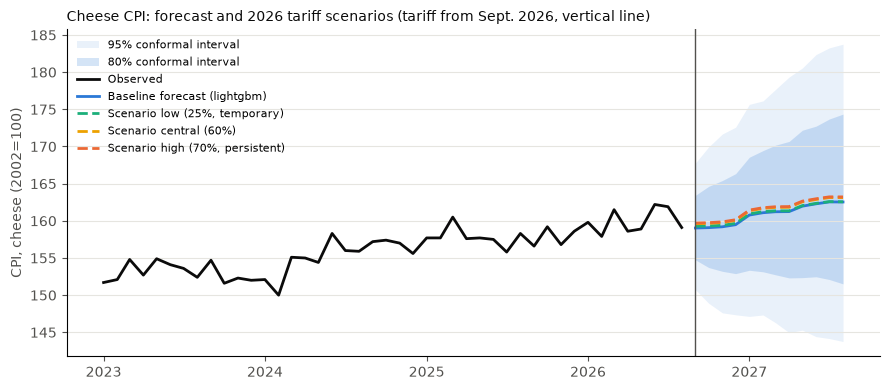

In [11]:
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e", "#e6e5e0"
hist = panel["Cheese"].loc["2023-01":]
fig, ax = plt.subplots(figsize=(9, 4))
t = pd.PeriodIndex(out.month, freq="M").to_timestamp()
ax.fill_between(t, out.lo95, out.hi95, color=BLUE, alpha=0.10, lw=0, label="95% conformal interval")
ax.fill_between(t, out.lo80, out.hi80, color=BLUE, alpha=0.20, lw=0, label="80% conformal interval")
ax.plot(hist.index.to_timestamp(), hist.values, color=INK, lw=2, label="Observed")
ax.plot(t, out.forecast, color=BLUE, lw=2, label=f"Baseline forecast ({best})")
for (name, col) in zip(scen, [AQUA, YELLOW, ORANGE]):
    ax.plot(t, out[name], color=col, lw=2, ls="--", label=f"Scenario {name}")
ax.axvline(first.to_timestamp(), color=MUTED, lw=1)
ax.set_ylabel("CPI, cheese (2002=100)", color=MUTED)
ax.tick_params(colors=MUTED)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("Cheese CPI: forecast and 2026 tariff scenarios (tariff from Sept. 2026, vertical line)", color=INK, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

## 6. Findings

Written up in D23 (decision log).